# Analisis Segmentasi Spesies Penguin Menggunakan K-Means Clustering
---
## 1. Business Understanding

### 1.1 Latar Belakang, Masalah, Solusi
1. **Latar Belakang**: Sebuah pusat konservasi margasatwa dan peneliti biologi kelautan ingin membangun sistem kecerdasan buatan berbasis Unsupervised Machine Learning untuk mengelompokkan karakteristik fisik populasi penguin secara otomatis ke dalam beberapa klaster kelompok morfologi tanpa perlu melakukan identifikasi manual secara terus-menerus di lapangan.
2. **Masalah**: Pusat konservasi tersebut masih mengelompokkan karakteristik fisik populasi penguin secara manual yang memakan waktu dan tenaga kerja.
3. **Solusi**: Membangun model *machine learning* berbasis algoritma **K-Means** untuk mengelompokkan populasi penguin secara otomatis dengan memanfaatkan dataset yang merekam berbagai ukuran anatomi tubuh penguin yang dimiliki oleh pusat konservasi tersebut.

### 1.2 Deskripsi Kolom Dataset `penguins.csv`
| **Nama Kolom** | **Tipe Data** | **Keterangan** |
| :-- | :-- | :-- |
| `culmen_length_mm` | `float64` | Panjang paruh penguin (culmen length) (satuan: milimeter). |
| `culmen_depth_mm` | `float64` | Kedalaman paruh penguin (culmen depth) (satuan: milimeter). |
| `flipper_length_mm` | `float64` | Panjang sirip penguin (flipper length) (satuan: milimeter). |
| `body_mass_g` | `float64` | Berat badan penguin (satuan: gram). |
| `sex` | `str` | Jenis kelamin penguin (MALE / FEMALE). |

---
## 2. Data Preparation

### 2.1 Import Library

In [77]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk

### 2.2 Load Dataset

In [78]:
df = pd.read_csv('penguins.csv', na_values=["NA", "NaN", ".", ""])
df.columns = df.columns.str.strip()

### 2.3 Tampilkan Data Teratas dan Data Terbawah

In [79]:
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [80]:
df.tail()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
339,NaN,NaN,NaN,NaN,NaN
340,46.8,14.3,215.0,4850.0,FEMALE
341,50.4,15.7,222.0,5750.0,MALE
342,45.2,14.8,212.0,5200.0,FEMALE
343,49.9,16.1,213.0,5400.0,MALE


### 2.4 Tampilkan Informasi Data

In [81]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                334 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB


### 2.5 Memeriksa Dimensi Data, Jumlah Data, Missing Value, dan Data Dupliakt

In [82]:
print(f'Dimensi Kolom: {df.shape}')
print(f'Jumlah Data: {df.size}')

print(f'\nJumlah Missing Value: {df.isnull().sum().sum()}')
print(f'---- Missing Value Pada Setiap olom ----\n{df.isnull().sum()[df.isnull().sum() > 0]}')

print(f'\nData Duplikat: {df.duplicated().sum()}')

Dimensi Kolom: (344, 5)
Jumlah Data: 1720

Jumlah Missing Value: 18
---- Missing Value Pada Setiap olom ----
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64

Data Duplikat: 1


---
## 3. Explaratory Data Analysis (EDA)

### 3.1 Tampilkan Deskripsi Data

In [83]:
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


### 3.2 Memeriksa Outlier dengan IQR dan Z-Score

In [84]:
outliers = []

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

for col in numeric_cols:
    if col in df.columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        median = df[col].median()
        mean = df[col].mean()
        std = df[col].std()
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        z_score = (df[col] - mean) / std
        outlier_iqr = df[(df[col] < lower) | (df[col] > upper)]
        outlier_z_score = df[np.abs(z_score) > 3]
        
        outliers.append({
            'nama kolom': col,
            'mean': mean,
            'standar deviasi': std,
            'min': df[col].min(),
            'q1': q1,
            'median': median,
            'q3': q3,
            'max': df[col].max(),
            'batas bawah': lower,
            'batas atas': upper,
            'outlier (IQR)': outlier_iqr.shape[0],
            'outlier (Z-Score)': outlier_z_score.shape[0],
        })
        

pd.DataFrame(outliers)

,nama kolom,mean,standar deviasi,min,q1,median,q3,max,batas bawah,batas atas,outlier (IQR),outlier (Z-Score)
0,culmen_length_mm,43.921930,5.459584,32.1,39.225,44.45,48.50,59.6,25.3125,62.4125,0,0
1,culmen_depth_mm,17.151170,1.974793,13.1,15.600,17.30,18.70,21.5,10.9500,23.3500,0,0
2,flipper_length_mm,214.014620,260.558057,-132.0,190.000,197.00,213.75,5000.0,154.3750,249.3750,2,1
3,body_mass_g,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.00,6300.0,1750.0000,6550.0000,0,0


### 3.3 Visualisasi Outlier Dengan Bxplot

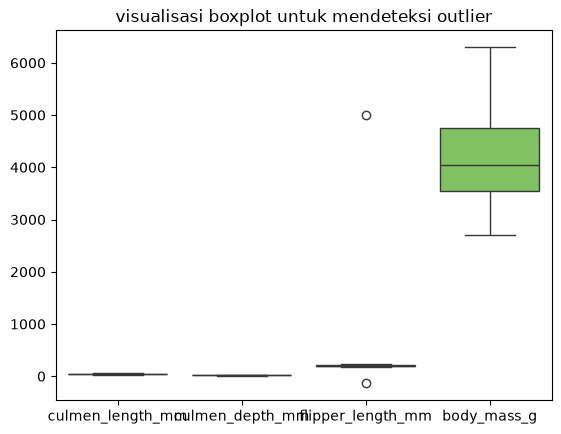

In [85]:
sns.boxplot(data=df[numeric_cols], palette='viridis')
plt.title('visualisasi boxplot untuk mendeteksi outlier')
plt.show()

### 3.4 Visualisasi Distribusi Data Pada Kolom Numerik

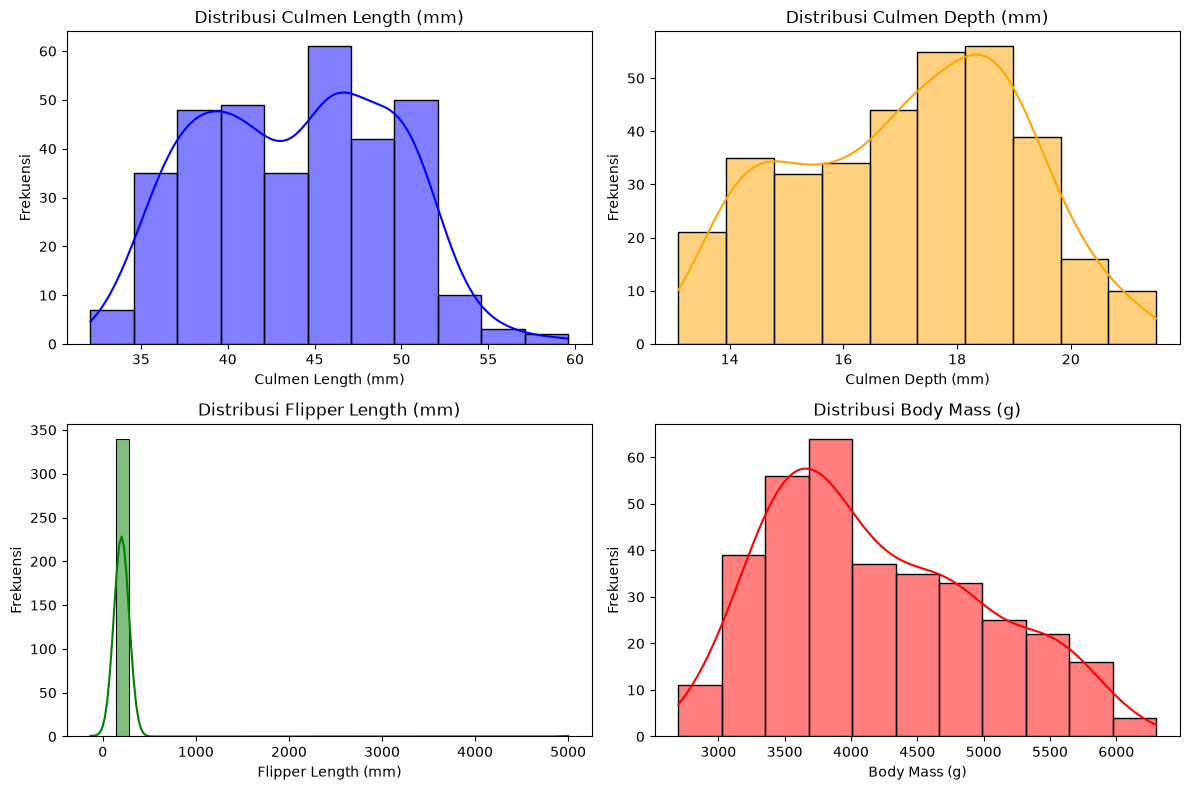

In [86]:
figure, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data=df, x='culmen_length_mm', kde=True, color='blue', ax=axes[0,0])
axes[0,0].set_title('Distribusi Culmen Length (mm)')
axes[0,0].set_xlabel('Culmen Length (mm)')
axes[0,0].set_ylabel('Frekuensi')

sns.histplot(data=df, x='culmen_depth_mm', kde=True, color='orange', ax=axes[0,1])
axes[0,1].set_title('Distribusi Culmen Depth (mm)')
axes[0,1].set_xlabel('Culmen Depth (mm)')
axes[0,1].set_ylabel('Frekuensi')

sns.histplot(data=df, x='flipper_length_mm', kde=True, color='green', ax=axes[1,0])
axes[1,0].set_title('Distribusi Flipper Length (mm)')
axes[1,0].set_xlabel('Flipper Length (mm)')
axes[1,0].set_ylabel('Frekuensi')

sns.histplot(data=df, x='body_mass_g', kde=True, color='red', ax=axes[1,1])
axes[1,1].set_title('Distribusi Body Mass (g)')
axes[1,1].set_xlabel('Body Mass (g)')
axes[1,1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

### 3.5 Analisis Korelasi Data Numerik

In [87]:
var_list = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
korelasi = []

for i in range(len(var_list)):
    for j in range(i + 1, len(var_list)):
        var1 = var_list[i]
        var2 = var_list[j]
        clean_df = df[[var1, var2]].dropna()
        pearson = clean_df[var1].corr(clean_df[var2], method='pearson')
        spearman = clean_df[var1].corr(clean_df[var2], method='spearman')
        kendall = clean_df[var1].corr(clean_df[var2], method='kendall')
        
        korelasi.append({
            'pasangan variabel': f'{var1} & {var2}',
            'korelasi pearson': pearson,
            'korelasi spearman': spearman,
            'korelasi kendall': kendall
        })
        
pd.DataFrame(korelasi)

,pasangan variabel,korelasi pearson,korelasi spearman,korelasi kendall
0,culmen_length_mm & culmen_depth_mm,-0.235053,-0.221749,-0.122850
1,culmen_length_mm & flipper_length_mm,0.022697,0.673734,0.484480
2,culmen_length_mm & body_mass_g,0.595110,0.583800,0.433359
3,culmen_depth_mm & flipper_length_mm,0.044643,-0.516687,-0.279936
4,culmen_depth_mm & body_mass_g,-0.471916,-0.432372,-0.195070
5,flipper_length_mm & body_mass_g,0.049355,0.833294,0.653700


### 3.6 Visualisasi Matriks Korelasi Dengan Heatmap

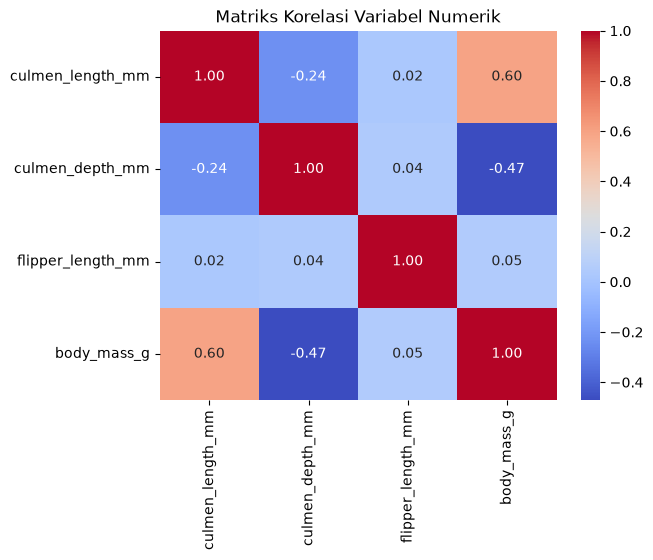

In [88]:
korelasi = df[var_list].corr(method='pearson')
sns.heatmap(korelasi, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriks Korelasi Variabel Numerik')
plt.show()

### 3.7 Visualisasi Scatter Plot culmen length dengan culmen depth

<Axes: xlabel='culmen_length_mm', ylabel='culmen_depth_mm'>

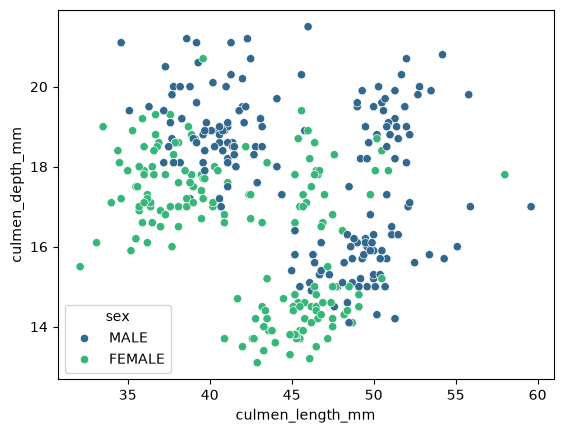

In [89]:
sns.scatterplot(data=df, x='culmen_length_mm', y='culmen_depth_mm', hue='sex', palette='viridis')

In [90]:
print(df.isnull().sum())
print(df.duplicated().sum())

culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64
1


In [91]:
df = df.dropna()
df = df.drop_duplicates()
print(df.isnull().sum())
print(df.duplicated().sum())


culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64
0


In [92]:
q1 = df['flipper_length_mm'].quantile(0.25)
q3 = df['flipper_length_mm'].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

df = df[(df['flipper_length_mm'] > lower) & (df['flipper_length_mm'] < upper)]

outlier = df[(df['flipper_length_mm'] < lower) | (df['flipper_length_mm'] > upper)]
print(outlier.shape[0])

0


In [93]:
df = df[df['sex'].isin((['MALE', 'FEMALE']))]

In [94]:
df = df.reset_index(drop=True)

<Axes: >

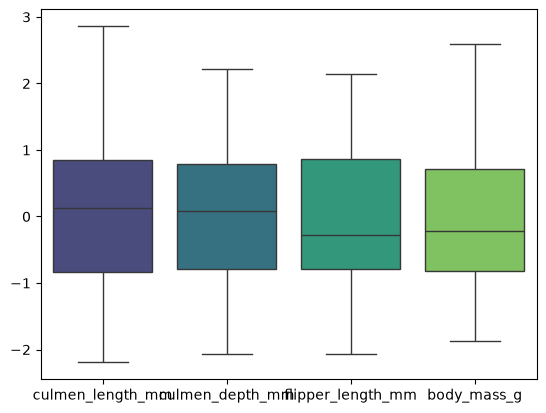

In [95]:
numeric_features = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
X = df[numeric_features]

mean_val = X.mean()
std_val = X.std(ddof=0)

X_scaled = (X - mean_val) / std_val

sns.boxplot(data=X_scaled, palette='viridis')

In [96]:
X_scaled

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,-0.903906,0.790360,-1.425342,-0.566948
1,-0.830434,0.126187,-1.068577,-0.504847
2,-0.683490,0.432728,-0.426399,-1.187953
3,-1.344738,1.096901,-0.569105,-0.939551
4,-0.867170,1.761074,-0.783164,-0.691149
...,...,...,...,...
327,0.583904,-1.764152,0.929309,0.892415
328,0.510432,-1.457611,1.000662,0.799264
329,1.171681,-0.742347,1.500134,1.917074
330,0.216543,-1.202160,0.786603,1.233968


---
## 7. GUI

In [100]:
def predic_cluster():
    try:
    
        colmen_length = entryCulmenLength.get().strip()
        colmen_depth = entryCulmenDepth.get().strip()
        flipper_length = entryFlipperLength.get().strip()
        body_mass = entryBodyMass.get().strip()
    
        if not all((colmen_length, colmen_depth, flipper_length, body_mass)):
            raise ValueError("Semua kolom harus diisi.")

        colmen_length = float(colmen_length)
        colmen_depth = float(colmen_depth)
        flipper_length = float(flipper_length)
        body_mass = float(body_mass)
    
        sex = segSex.get()

_IncompleteInputError: incomplete input (2614902119.py, line 17)

In [ ]:
from customtkinter import *

app = CTk()
app.title('Segmentasi Spesies Penguin')

lebar = 600
tinggi = 700
screen_width = app.winfo_screenwidth()
screen_height = app.winfo_screenheight()
x = int((screen_width / 2) - (lebar / 2))
y = int((screen_height / 2) - (tinggi / 2))
app.geometry(f"{lebar}x{tinggi}+{x}+{y}")
set_appearance_mode('light')

Title = CTkLabel(app, text="Analisis Segmentasi Spesies Penguin", font=("Arial", 24, "bold"))
Title.pack(pady=20)

MainFrame = CTkFrame(app, fg_color="#fff",  corner_radius=12)
MainFrame.pack(padx=10, pady=(0, 20), fill="both", expand=True)

lblCulmenLength = CTkLabel(MainFrame, text="Panjang Paruh Penguin (Satuan: milimeter)", font=("Arial", 16), justify="left")
lblCulmenLength.pack(pady=(20, 5), padx=20, anchor="w")
entryCulmenLength = CTkEntry(MainFrame, placeholder_text="Masukkan Panjang Paruh Penguin (e.g. 39.5)")
entryCulmenLength.pack(padx=20, pady=(0, 20), fill="both")

lblCulmenDepth = CTkLabel(MainFrame, text="Kedalaman Paruh Penguin (Satuan: milimeter)", font=("Arial", 16), justify="left")
lblCulmenDepth.pack(padx=20, pady=(0,5), anchor="w")
entryCulmenDepth = CTkEntry(MainFrame, placeholder_text="Masukkan Kedalaman Paruh Penguin (e.g. 17.4)")
entryCulmenDepth.pack(padx=20, pady=(0, 20), fill="both")

lblFlipperLength = CTkLabel(MainFrame, text="Panjang Sirip Pinguin (Satuan: milimeter)", font=("Arial", 16), justify="left")
lblFlipperLength.pack(padx=20, pady=(0,5), anchor="w")
entryFlipperLength = CTkEntry(MainFrame, placeholder_text="Masukkan Panjang Sirip Penguin (e.g. 186)")
entryFlipperLength.pack(padx=20, pady=(0, 20), fill="both")

lblBodyMass = CTkLabel(MainFrame, text="Berat Badan Pinguin (Satuan: gram)", font=("Arial", 16), justify="left")
lblBodyMass.pack(padx=20, pady=(0,5), anchor="w")
entryBodyMass = CTkEntry(MainFrame, placeholder_text="Masukkan Berat Badan Penguin (e.g. 3800)")
entryBodyMass.pack(padx=20, pady=(0, 20), fill="both")

lblBodyMass = CTkLabel(MainFrame, text="Jenis Kelamin Pinguin", font=("Arial", 16), justify="left")
lblBodyMass.pack(padx=20, pady=(0,5), anchor="w")
segSex = CTkSegmentedButton(MainFrame, values=["Male", "Female"], fg_color="#fff")
segSex.pack(padx=20, pady=(0, 20), fill="both")

btnPredict = CTkButton(app, text="Prediksi Kelompok Penguin", font=("Arial", 16), command=predict_cluster)
btnPredict.pack(padx=20, pady=(20,5), fill="both")

lblPredict = CTkLabel(app, text="Hasil Prediksi: -", font=("Arial", 16), justify="center")
lblPredict.pack(padx=20, pady=(0, 30), fill="x")

app.mainloop()